# Notebook to extend the files for CoLoRe
### filling $n(z), b(z), T(z)$ files from $z=0$ to $z=3.8$ 

The original LSST files that Laura sent me, and got from either papers or someone, don't span the same redshift range as CoLoRe does. CoLoRe raises errors if the redshift range of the files don't span all the redshift of the simulation 
(However, if the redshift range of the files span further than the simulation redshift then this is not a problem for CoLoRe. Those redshifts will just be ignored). 
Thus, one has to manually fill the remaining redshift of all the files used.
- Redshift distributions $n(z)$ are filled with zeros
- Tunning bias $b(z)$ are interpolated
- Tunning thresholds $T(z)$ are interpolated

Actually, interpolation is not strictly needed as long as the respective $n(z)$ are zero outside its original range.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

In [4]:
zmax = 3.8

## extended DESI galaxies

In [3]:
# load the nz
z_nz_bgs, nz_bgs = np.loadtxt("nz/nz_desi_bgs_original.txt", unpack=True)

# fill n(z) values elsewhere with 0
dz = z_nz_bgs[1] - z_nz_bgs[0]

# build the zero-padding regions
# we use dz/2 offsets to avoid floating-point boundary overlaps
z_prefix = np.arange(0, z_nz_bgs[0], dz)
z_suffix = np.arange(z_nz_bgs[-1] + dz, zmax + dz, dz)

# concatenate the redshifts and the n(z) values directly
z_nz_bgs_new = np.concatenate([z_prefix, z_nz_bgs, z_suffix])
nz_bgs_new = np.concatenate([np.zeros_like(z_prefix), nz_bgs, np.zeros_like(z_suffix)])

# save the perfectly preserved distribution
output_filename = "nz/nz_desi_bgs.txt"
new_data = np.column_stack((z_nz_bgs_new, nz_bgs_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

In [4]:
# load the nz
z_nz_lrg, nz_lrg = np.loadtxt("nz/nz_desi_lrg.txt", unpack=True)

# fill n(z) values elsewhere with 0
dz = z_nz_lrg[1] - z_nz_lrg[0]

# build the zero-padding regions
# we use dz/2 offsets to avoid floating-point boundary overlaps
z_prefix = np.arange(0, z_nz_lrg[0], dz)
z_suffix = np.arange(z_nz_lrg[-1] + dz, zmax + dz, dz)

# concatenate the redshifts and the n(z) values directly
z_nz_lrg_new = np.concatenate([z_prefix, z_nz_lrg, z_suffix])
nz_lrg_new = np.concatenate([np.zeros_like(z_prefix), nz_lrg, np.zeros_like(z_suffix)])

# save the perfectly preserved distribution
output_filename = "nz/nz_desi_lrg.txt"
new_data = np.column_stack((z_nz_lrg_new, nz_lrg_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

In [5]:
# load the nz
z_nz_elg, nz_elg = np.loadtxt("nz/nz_desi_elg.txt", unpack=True)

# fill n(z) values elsewhere with 0
dz = z_nz_elg[1] - z_nz_elg[0]

# build the zero-padding regions
# we use dz/2 offsets to avoid floating-point boundary overlaps
z_prefix = np.arange(0, z_nz_elg[0], dz)
z_suffix = np.arange(z_nz_elg[-1] + dz, zmax + dz, dz)

# concatenate the redshifts and the n(z) values directly
z_nz_elg_new = np.concatenate([z_prefix, z_nz_elg, z_suffix])
nz_elg_new = np.concatenate([np.zeros_like(z_prefix), nz_elg, np.zeros_like(z_suffix)])

# save the perfectly preserved distribution
output_filename = "nz/nz_desi_elg.txt"
new_data = np.column_stack((z_nz_elg_new, nz_elg_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

In [6]:
# load the nz
z_nz_qso, nz_qso = np.loadtxt("nz/nz_desi_qso.txt", unpack=True)

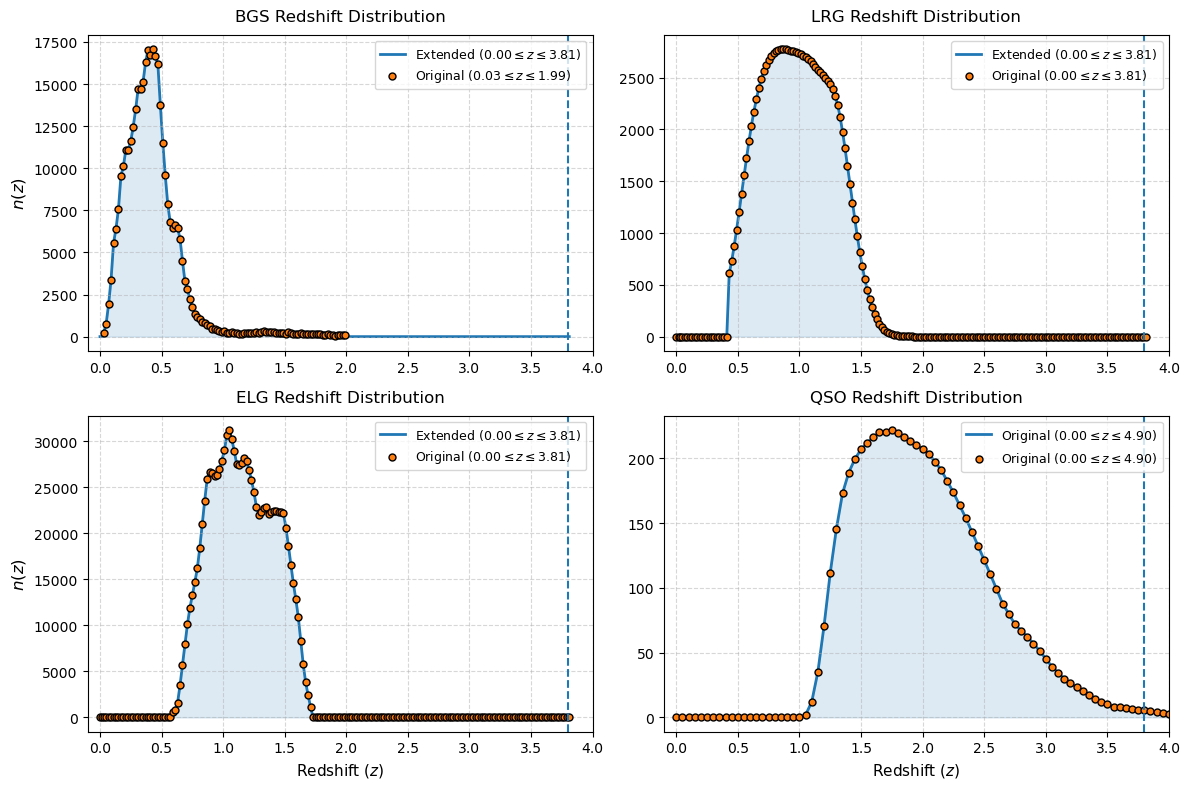

In [7]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8), dpi=100)
axs = axs.flatten()

# =====================================================================
# SUBPLOT 1: DESI BGS Distribution n(z)
# =====================================================================
axs[0].plot(
    z_nz_bgs_new,
    nz_bgs_new,
    label=rf"Extended (${z_nz_bgs_new.min():.2f} \leq z \leq {z_nz_bgs_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[0].fill_between(z_nz_bgs_new, nz_bgs_new, color="tab:blue", alpha=0.15)
axs[0].scatter(
    z_nz_bgs,
    nz_bgs,
    label=rf"Original (${z_nz_bgs.min():.2f} \leq z \leq {z_nz_bgs.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[0].set_title("BGS Redshift Distribution", fontsize=12, pad=10)
axs[0].legend(fontsize=9, loc="upper right")

# =====================================================================
# SUBPLOT 2: DESI LRG Distribution n(z)
# =====================================================================

axs[1].plot(
    z_nz_lrg_new,
    nz_lrg_new,
    label=rf"Extended (${z_nz_lrg_new.min():.2f} \leq z \leq {z_nz_lrg_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[1].fill_between(z_nz_lrg_new, nz_lrg_new, color="tab:blue", alpha=0.15)
axs[1].scatter(
    z_nz_lrg,
    nz_lrg,
    label=rf"Original (${z_nz_lrg.min():.2f} \leq z \leq {z_nz_lrg.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[1].set_title("LRG Redshift Distribution", fontsize=12, pad=10)
axs[1].legend(fontsize=9, loc="upper right")

# =====================================================================
# SUBPLOT 3: DESI ELG Distribution n(z)
# =====================================================================

axs[2].plot(
    z_nz_elg_new,
    nz_elg_new,
    label=rf"Extended (${z_nz_elg_new.min():.2f} \leq z \leq {z_nz_elg_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[2].fill_between(z_nz_elg_new, nz_elg_new, color="tab:blue", alpha=0.15)
axs[2].scatter(
    z_nz_elg,
    nz_elg,
    label=rf"Original (${z_nz_elg.min():.2f} \leq z \leq {z_nz_elg.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[2].set_title("ELG Redshift Distribution", fontsize=12, pad=10)
axs[2].legend(fontsize=9, loc="upper right")

# =====================================================================
# SUBPLOT 4: DESI QSO Distribution n(z)
# =====================================================================

axs[3].plot(
    z_nz_qso,
    nz_qso,
    label=rf"Original (${z_nz_qso.min():.2f} \leq z \leq {z_nz_qso.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[3].fill_between(z_nz_qso, nz_qso, color="tab:blue", alpha=0.15)
axs[3].scatter(
    z_nz_qso,
    nz_qso,
    label=rf"Original (${z_nz_qso.min():.2f} \leq z \leq {z_nz_qso.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[3].set_title("QSO Redshift Distribution", fontsize=12, pad=10)
axs[3].legend(fontsize=9, loc="upper right")

# =====================================================================
# GLOBAL STYLING & CLEANUP
# =====================================================================

axs[2].set_xlabel("Redshift ($z$)", fontsize=11)
axs[3].set_xlabel("Redshift ($z$)", fontsize=11)
axs[0].set_ylabel("$n(z)$", fontsize=12)
axs[2].set_ylabel("$n(z)$", fontsize=12)
for ax in axs:
    ax.set_xlim(-0.1, 4.0)
    ax.axvline(x=3.8, ls='--')
    ax.grid(True, linestyle="--", alpha=0.5)

# Tight layout handles padding automatically so text doesn't overlap
plt.tight_layout()
plt.savefig("./plots/DESI_extended_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## extended LSST-tunning galaxies

In [8]:
# load the bz
z_bz, bz = np.loadtxt("bz-tunning/bz-tunning_lsst_gal_original.txt", unpack=True)

# Define the new grid parameters
dz = z_bz[1] - z_bz[0]
z_bz_new = np.arange(0, zmax + dz, dz)

# Create a smooth, non-linear interpolator
# extrapolate=True allows the cubic trend to carry past the boundaries
interp_func = PchipInterpolator(z_bz, bz, extrapolate=True)
bz_new = interp_func(z_bz_new)

# save the distribution
output_filename = "bz-tunning/bz_tunning_lsst_gal.txt"
new_data = np.column_stack((z_bz_new, bz_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

In [9]:
# load the Tz
z_Tz, Tz = np.loadtxt("Tz/Tz_lsst_gal_original.txt", unpack=True)

# Define the new grid parameters
dz = z_Tz[1] - z_Tz[0]
z_Tz_new = np.arange(0, zmax + dz, dz)

# Create a smooth, non-linear interpolator
# extrapolate=True allows the cubic trend to carry past the boundaries
interp_func = PchipInterpolator(z_Tz, Tz, extrapolate=True)
Tz_new = interp_func(z_Tz_new)

# save the perfectly preserved distribution
output_filename = "Tz/Tz_lsst_gal.txt"
new_data = np.column_stack((z_Tz_new, Tz_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

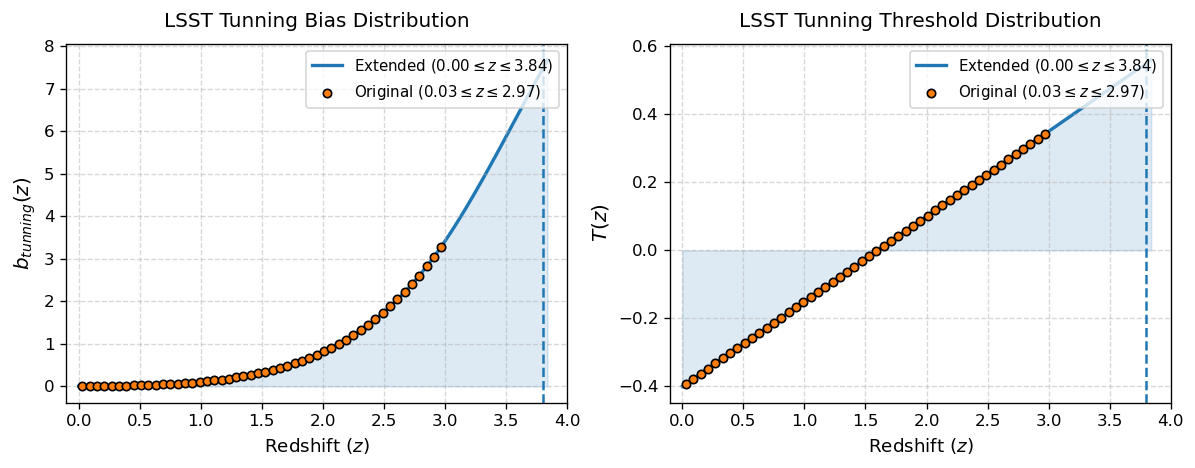

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True, dpi=120)

# =====================================================================
# SUBPLOT 2: Bias Distribution b(z)
# =====================================================================
axs[0].plot(
    z_bz_new,
    bz_new,
    label=rf"Extended (${z_bz_new.min():.2f} \leq z \leq {z_bz_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[0].fill_between(z_bz_new, bz_new, color="tab:blue", alpha=0.15)
axs[0].scatter(
    z_bz,
    bz,
    label=rf"Original (${z_bz.min():.2f} \leq z \leq {z_bz.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[0].set_title("LSST Tunning Bias Distribution", fontsize=12, pad=10)
axs[0].set_ylabel("$b_{tunning}(z)$", fontsize=12)
axs[0].legend(fontsize=9, loc="upper right")

# =====================================================================
# SUBPLOT 3: Threshold Distribution T(z)
# =====================================================================
axs[1].plot(
    z_Tz_new,
    Tz_new,
    label=rf"Extended (${z_Tz_new.min():.2f} \leq z \leq {z_Tz_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[1].fill_between(z_Tz_new, Tz_new, color="tab:blue", alpha=0.15)
axs[1].scatter(
    z_Tz,
    Tz,
    label=rf"Original (${z_Tz.min():.2f} \leq z \leq {z_Tz.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[1].set_title("LSST Tunning Threshold Distribution", fontsize=12, pad=10)
axs[1].set_ylabel("$T(z)$", fontsize=12)
axs[1].legend(fontsize=9, loc="upper right")

# =====================================================================
# GLOBAL STYLING & CLEANUP
# =====================================================================
for ax in axs:
    ax.set_xlabel("Redshift ($z$)", fontsize=11)
    ax.set_xlim(-0.1, 4.0)
    ax.axvline(x=3.8, ls='--')
    ax.grid(True, linestyle="--", alpha=0.5)

# Tight layout handles padding automatically so text doesn't overlap
plt.tight_layout()
plt.savefig("./plots/LSST_extended_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

## LSST galaxies

In [11]:
# load the nz
z_nz, nz = np.loadtxt("nz/nz_lsst_gal_original.txt", unpack=True)

# fill n(z) values elsewhere with 0
dz = z_nz[1] - z_nz[0]

# build the zero-padding regions
# we use dz/2 offsets to avoid floating-point boundary overlaps
z_prefix = np.arange(0, z_nz[0], dz)
z_suffix = np.arange(z_nz[-1] + dz, zmax + dz, dz)

# concatenate the redshifts and the n(z) values directly
z_nz_new = np.concatenate([z_prefix, z_nz, z_suffix])
nz_new = np.concatenate([np.zeros_like(z_prefix), nz, np.zeros_like(z_suffix)])

# save the perfectly preserved distribution
output_filename = "nz/nz_lsst_gal.txt"
new_data = np.column_stack((z_nz_new, nz_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

In [12]:
# load the bz
z_bz, bz = np.loadtxt("bz/bz_lsst_gal.txt", unpack=True)

# Define the new grid parameters
dz = z_bz[1] - z_bz[0]

# Build a continuous redshift grid from 0 to 3.8
# Adding dz/2 ensures the endpoint zmax is safely included 
z_bz_new = np.arange(0, zmax + dz, dz)

# Create a smooth, non-linear interpolator
# extrapolate=True allows the cubic trend to carry past the boundaries
interp_func = PchipInterpolator(z_bz, bz, extrapolate=True)
bz_new = interp_func(z_bz_new)

# save the distribution
output_filename = "bz/bz_lsst_gal.txt"
new_data = np.column_stack((z_bz_new, bz_new))
np.savetxt(output_filename, new_data, fmt="%.18e")

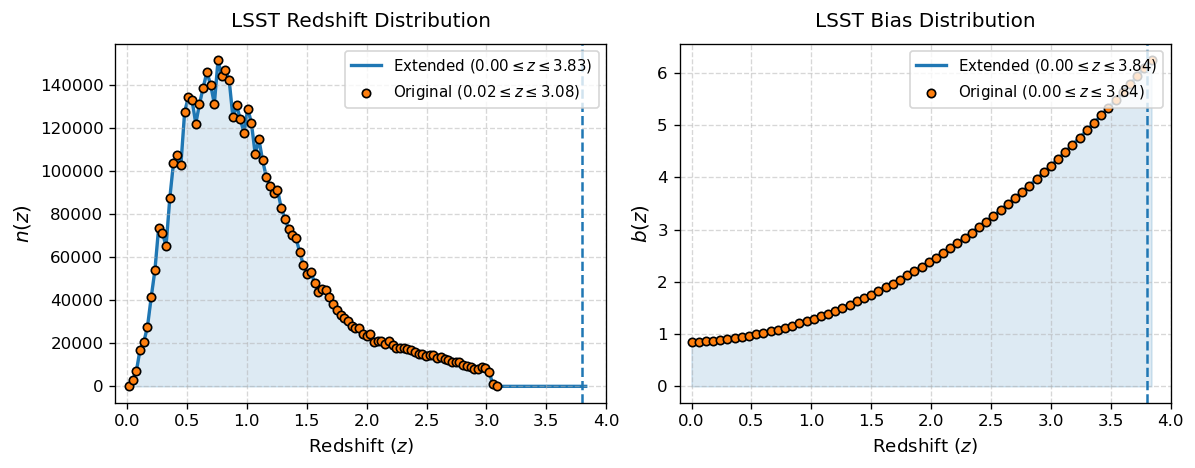

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True, dpi=120)

# =====================================================================
# SUBPLOT 1: Redshift Distribution n(z)
# =====================================================================
axs[0].plot(
    z_nz_new,
    nz_new,
    label=rf"Extended (${z_nz_new.min():.2f} \leq z \leq {z_nz_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[0].fill_between(z_nz_new, nz_new, color="tab:blue", alpha=0.15)
axs[0].scatter(
    z_nz,
    nz,
    label=rf"Original (${z_nz.min():.2f} \leq z \leq {z_nz.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[0].set_title("LSST Redshift Distribution", fontsize=12, pad=10)
axs[0].set_ylabel("$n(z)$", fontsize=12)
axs[0].legend(fontsize=9, loc="upper right")

# =====================================================================
# SUBPLOT 2: Bias Distribution b(z)
# =====================================================================
axs[1].plot(
    z_bz_new,
    bz_new,
    label=rf"Extended (${z_bz_new.min():.2f} \leq z \leq {z_bz_new.max():.2f}$)",
    color="tab:blue",
    lw=2,
    zorder=1,
)
axs[1].fill_between(z_bz_new, bz_new, color="tab:blue", alpha=0.15)
axs[1].scatter(
    z_bz,
    bz,
    label=rf"Original (${z_bz.min():.2f} \leq z \leq {z_bz.max():.2f}$)",
    color="tab:orange",
    edgecolor="black",
    s=25,
    zorder=2,
)
axs[1].set_title("LSST Bias Distribution", fontsize=12, pad=10)
axs[1].set_ylabel("$b(z)$", fontsize=12)
axs[1].legend(fontsize=9, loc="upper right")


# =====================================================================
# GLOBAL STYLING & CLEANUP
# =====================================================================
for ax in axs:
    ax.set_xlabel("Redshift ($z$)", fontsize=11)
    ax.set_xlim(-0.1, 4.0)
    ax.axvline(x=3.8, ls='--')
    ax.grid(True, linestyle="--", alpha=0.5)

# Tight layout handles padding automatically so text doesn't overlap
plt.tight_layout()
#plt.savefig("./plots/LSST_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

# Redshift and bias distribution of all galaxies

In [16]:
# load the nz
z_nz_bgs, nz_bgs = np.loadtxt("nz/nz_desi_bgs.txt", unpack=True)
z_nz_lrg, nz_lrg = np.loadtxt("nz/nz_desi_lrg.txt", unpack=True)
z_nz_elg, nz_elg = np.loadtxt("nz/nz_desi_elg.txt", unpack=True)
z_nz_qso, nz_qso = np.loadtxt("nz/nz_desi_qso.txt", unpack=True)
z_nz_lsst, nz_lsst = np.loadtxt("nz/nz_lsst_gal.txt", unpack=True)

z_nz_array = [z_nz_bgs, z_nz_lrg, z_nz_elg, z_nz_qso, z_nz_lsst]
nz_array = [nz_bgs, nz_lrg, nz_elg, nz_qso, nz_lsst]

fsky = (4 * np.pi) * (180 / np.pi)**2  # multiply by the total sky area in deg**2 and redshift bin width
for i in range(len(nz_array)):
    nz_array[i] = nz_array[i] * fsky
    nz_array[i] = nz_array[i]/np.sum(nz_array[i])  # normalize to unity

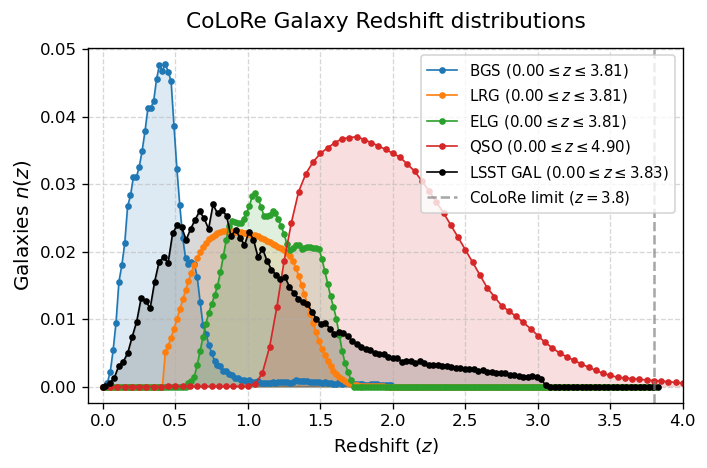

In [17]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=120)

# Map tracers to their respective data variables and colors for differentiation
tracers = [
    ("BGS", z_nz_array[0], nz_array[0], "tab:blue"),
    ("LRG", z_nz_array[1], nz_array[1], "tab:orange"),
    ("ELG", z_nz_array[2], nz_array[2], "tab:green"),
    ("QSO", z_nz_array[3], nz_array[3], "tab:red"),
    ("LSST GAL", z_nz_array[4], nz_array[4], "black"),
]

# Overlay each tracer using the line + fill_between + scatter combo style
for name, z, nz, color in tracers:
    label_str = rf"{name} (${z.min():.2f} \leq z \leq {z.max():.2f}$)"
    
    # Continuous trend line
    ax.plot(z, nz, label=label_str, color=color, lw=1, ls='-', marker='.')
    ax.fill_between(z, 0, nz, color=color, alpha=0.15)


# =====================================================================
# 3. GLOBAL STYLING & CLEANUP
# =====================================================================
ax.set_title("CoLoRe Galaxy Redshift distributions", fontsize=13, pad=12)
ax.set_xlabel("Redshift ($z$)", fontsize=11)
ax.set_ylabel("Galaxies $n(z)$", fontsize=12)

# Apply the requested axis ranges, vertical line constraint, and grid styles
ax.set_xlim(-0.1, 4.0)
ax.axvline(x=3.8, ls='--', color='gray', alpha=0.7, label="CoLoRe limit ($z=3.8$)")
ax.grid(True, linestyle="--", alpha=0.5)

# Place legend in a clear corner with your specified text sizing
ax.legend(fontsize=9)

# Handle padding automatically so elements don't clip
plt.tight_layout()
plt.savefig("./plots/galaxies_nz.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
# load the nz
z_bz_bgs, bz_bgs = np.loadtxt("bz/bz_desi_bgs.txt", unpack=True)
z_bz_lrg, bz_lrg = np.loadtxt("bz/bz_desi_lrg.txt", unpack=True)
z_bz_elg, bz_elg = np.loadtxt("bz/bz_desi_elg.txt", unpack=True)
z_bz_qso, bz_qso = np.loadtxt("bz/bz_desi_qso.txt", unpack=True)
z_bz_lsst, bz_lsst = np.loadtxt("bz/bz_lsst_gal.txt", unpack=True)

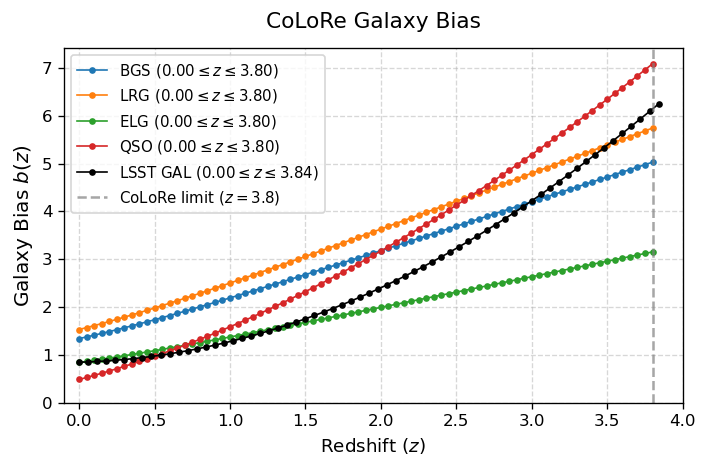

In [19]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=120)

# Map tracers to their respective data variables and colors for differentiation
tracers = [
    ("BGS", z_bz_bgs, bz_bgs, "tab:blue"),
    ("LRG", z_bz_lrg, bz_lrg, "tab:orange"),
    ("ELG", z_bz_elg, bz_elg, "tab:green"),
    ("QSO", z_bz_qso, bz_qso, "tab:red"),
    ("LSST GAL", z_bz_lsst, bz_lsst, "black"),
]

# Overlay each tracer using the line + fill_between + scatter combo style
for name, z, bz, color in tracers:
    label_str = rf"{name} (${z.min():.2f} \leq z \leq {z.max():.2f}$)"
    
    # Continuous trend line
    ax.plot(z, bz, label=label_str, color=color, lw=1, ls='-', marker='.')

# =====================================================================
# 3. GLOBAL STYLING & CLEANUP
# =====================================================================
ax.set_title("CoLoRe Galaxy Bias", fontsize=13, pad=12)
ax.set_xlabel("Redshift ($z$)", fontsize=11)
ax.set_ylabel("Galaxy Bias $b(z)$", fontsize=12)

# Apply the requested axis ranges, vertical line constraint, and grid styles
ax.set_xlim(-0.1, 4.0)
ax.set_ylim(ymin=0)
ax.axvline(x=3.8, ls='--', color='gray', alpha=0.7, label="CoLoRe limit ($z=3.8$)")
ax.grid(True, linestyle="--", alpha=0.5)

# Place legend in a clear corner with your specified text sizing
ax.legend(fontsize=9, loc="upper left", )

# Handle padding automatically so elements don't clip
plt.tight_layout()
plt.savefig("./plots/galaxies_bz.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
# load the nz
z_bz_tunning_bgs, bz_tunning_bgs = np.loadtxt("bz-tunning/bz-tunning_desi_bgs.txt", unpack=True)
z_bz_tunning_lrg, bz_tunning_lrg = np.loadtxt("bz-tunning/bz-tunning_desi_lrg.txt", unpack=True)
z_bz_tunning_elg, bz_tunning_elg = np.loadtxt("bz-tunning/bz-tunning_desi_elg.txt", unpack=True)
z_bz_tunning_qso, bz_tunning_qso = np.loadtxt("bz-tunning/bz-tunning_desi_qso.txt", unpack=True)
z_bz_tunning_lsst, bz_tunning_lsst = np.loadtxt("bz-tunning/bz-tunning_lsst_gal.txt", unpack=True)

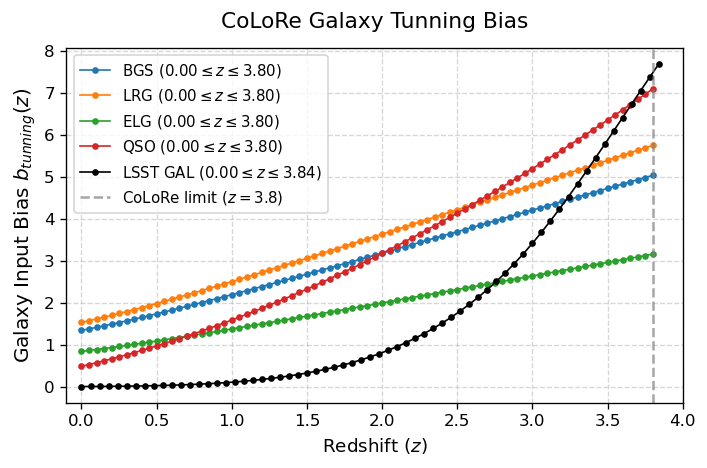

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=120)

# Map tracers to their respective data variables and colors for differentiation
tracers = [
    ("BGS", z_bz_tunning_bgs, bz_tunning_bgs, "tab:blue"),
    ("LRG", z_bz_tunning_lrg, bz_tunning_lrg, "tab:orange"),
    ("ELG", z_bz_tunning_elg, bz_tunning_elg, "tab:green"),
    ("QSO", z_bz_tunning_qso, bz_tunning_qso, "tab:red"),
    ("LSST GAL", z_bz_tunning_lsst, bz_tunning_lsst, "black"),
]

# Overlay each tracer using the line + fill_between + scatter combo style
for name, z, bz, color in tracers:
    label_str = rf"{name} (${z.min():.2f} \leq z \leq {z.max():.2f}$)"
    
    # Continuous trend line
    ax.plot(z, bz, label=label_str, color=color, lw=1, ls='-', marker='.')

# =====================================================================
# 3. GLOBAL STYLING & CLEANUP
# =====================================================================
ax.set_title("CoLoRe Galaxy Tunning Bias", fontsize=13, pad=12)
ax.set_xlabel("Redshift ($z$)", fontsize=11)
ax.set_ylabel("Galaxy Input Bias $b_{tunning}(z)$", fontsize=12)

# Apply the requested axis ranges, vertical line constraint, and grid styles
ax.set_xlim(-0.1, 4.0)
ax.axvline(x=3.8, ls='--', color='gray', alpha=0.7, label="CoLoRe limit ($z=3.8$)")
ax.grid(True, linestyle="--", alpha=0.5)

# Place legend in a clear corner with your specified text sizing
ax.legend(fontsize=9, loc="upper left", )

# Handle padding automatically so elements don't clip
plt.tight_layout()
plt.savefig("./plots/galaxies_bz_input.png", dpi=300, bbox_inches="tight")
plt.show()

In [20]:
# load the Tz
z_tz_bgs, tz_bgs = np.loadtxt("Tz/Tz_desi_bgs.txt", unpack=True)
z_tz_bgs_new, tz_bgs_new = np.loadtxt("Tz/Tz_desi_bgs_new.txt", unpack=True)
z_tz_lrg, tz_lrg = np.loadtxt("Tz/Tz_desi_lrg.txt", unpack=True)
z_tz_elg, tz_elg = np.loadtxt("Tz/Tz_desi_elg.txt", unpack=True)
z_tz_qso, tz_qso = np.loadtxt("Tz/Tz_desi_qso.txt", unpack=True)
z_tz_lsst, tz_lsst = np.loadtxt("Tz/Tz_lsst_gal.txt", unpack=True)

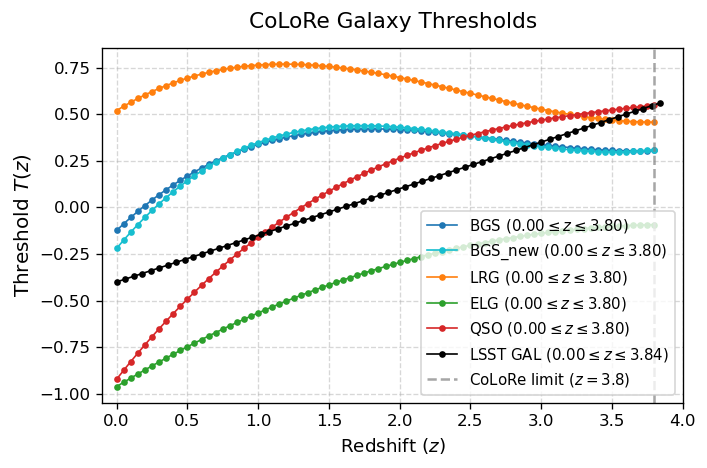

In [21]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=120)

# Map tracers to their respective data variables and colors for differentiation
tracers = [
    ("BGS", z_tz_bgs, tz_bgs, "tab:blue"),
    ("BGS_new", z_tz_bgs, tz_bgs_new, "tab:cyan"),
    ("LRG", z_tz_lrg, tz_lrg, "tab:orange"),
    ("ELG", z_tz_elg, tz_elg, "tab:green"),
    ("QSO", z_tz_qso, tz_qso, "tab:red"),
    ("LSST GAL", z_tz_lsst, tz_lsst, "black"),
]

# Overlay each tracer using the line + fill_between + scatter combo style
for name, z, tz, color in tracers:
    label_str = rf"{name} (${z.min():.2f} \leq z \leq {z.max():.2f}$)"
    
    # Continuous trend line
    ax.plot(z, tz, label=label_str, color=color, lw=1, ls='-', marker='.')


# =====================================================================
# 3. GLOBAL STYLING & CLEANUP
# =====================================================================
ax.set_title("CoLoRe Galaxy Thresholds", fontsize=13, pad=12)
ax.set_xlabel("Redshift ($z$)", fontsize=11)
ax.set_ylabel("Threshold $T(z)$", fontsize=12)

# Apply the requested axis ranges, vertical line constraint, and grid styles
ax.set_xlim(-0.1, 4.0)
ax.axvline(x=3.8, ls='--', color='gray', alpha=0.7, label="CoLoRe limit ($z=3.8$)")
ax.grid(True, linestyle="--", alpha=0.5)

# Place legend in a clear corner with your specified text sizing
ax.legend(fontsize=9)

# Handle padding automatically so elements don't clip
plt.tight_layout()
plt.savefig("./plots/galaxies_Tz.png", dpi=300, bbox_inches="tight")
plt.show()